# 24 — Figuras para el pre-informe

**Autor:** Jason Sepúlveda S.
**Proyecto:** Evaluación experimental de la extracción automática y la representación
persistente de decisiones organizacionales frente a Recuperación Aumentada (RAG)
**Depende de:** [`00-jss-corpus-y-auditoria.ipynb`](00-jss-corpus-y-auditoria.ipynb) ·
[`18-jss-anotacion-f2-adjudicacion.ipynb`](18-jss-anotacion-f2-adjudicacion.ipynb)

---

## Qué hace este notebook

Genera dos figuras del pre-informe y las exporta como PNG a
[`docs/entregables/figuras/`](../docs/entregables/figuras/):

1. **Autoría de las decisiones por rol** (§1): evidencia del sesgo del corpus hacia el jefe de proyecto.
2. **Acuerdo entre anotadores de la Fase 2** (§2): la confiabilidad de la referencia de OE1.

No se calcula nada nuevo. Las cifras salen de funciones testeadas de `src/afg/`
(`afg.audit.role_authorship` y `afg.annotation.pooled.pooled_agreement_report`), las mismas que usan los
notebooks 00 y 18, y el dibujo sale de `afg.eda.figures`. Solo se leen estadísticas agregadas (ADR 0005).

In [1]:
import warnings

import pandas as pd
from IPython.display import Markdown, display

from afg import audit
from afg.annotation.pooled import pooled_agreement_report
from afg.annotation.workspace import load_annotation_plan
from afg.eda.figures import (
    plot_agreement_by_axis,
    plot_role_authorship,
    report_style,
    save_figure,
)
from afg.eda.tables import format_thousands as es
from afg.shared.config import load_corpus_config
from afg.shared.paths import AMI_DIR, PROJECT_ROOT

# Cohen's kappa is undefined (NaN) when both annotators use one label; scikit-learn warns about it.
warnings.filterwarnings("ignore", module="sklearn")

FIGURES_DIR = PROJECT_ROOT / "docs" / "entregables" / "figuras"
EXPORTED = []

# Guard: the corpus is gitignored.
if not AMI_DIR.exists() or not any(AMI_DIR.glob("abstractive/*.xml")):
    raise SystemExit("Falta el corpus AMI. Ejecuta primero: uv run afg corpus download")

SERIES = load_corpus_config()["oe1"]["series"]
print(f"Series del corpus: {len(SERIES)}")

Series del corpus: 14


---

# 1. Autoría de las decisiones por rol

En el escenario del corpus cada participante tiene un rol: jefe de proyecto (PM), diseñador industrial (ID),
experto en marketing (ME) y diseñador de interfaz (UI). `afg.audit.role_authorship` cuenta, para cada decisión,
los actos de diálogo que la respaldan según los enlaces de la anotación del corpus y los atribuye al rol de
quien habló. Un acto es un evento de atribución; una decisión con tres actos de tres hablantes suma tres eventos.

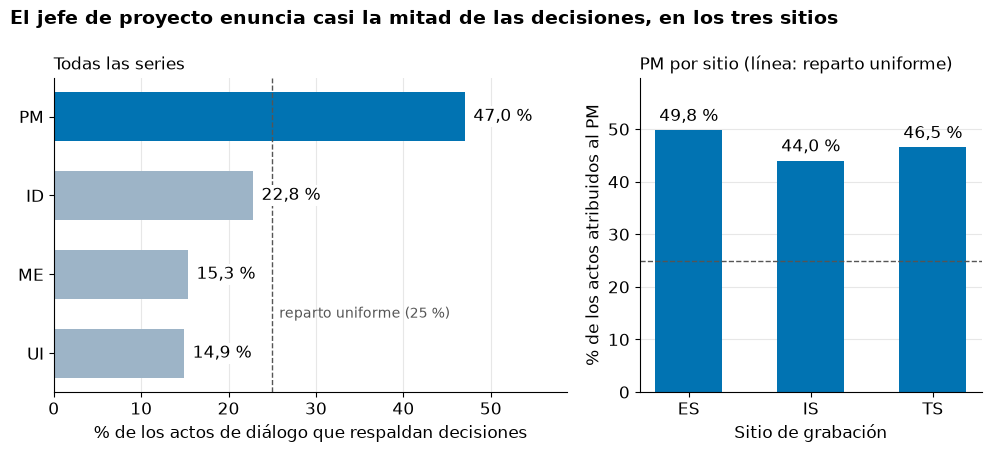

site,ALL,ES,IS,TS
role,,,,
ID,22.8,20.8,25.4,22.6
ME,15.3,15.1,12.0,18.9
PM,47.0,49.8,44.0,46.5
UI,14.9,14.3,18.7,12.0


Actos de diálogo atribuidos: 685
{'PM': 47.0, 'ID': 22.8, 'ME': 15.3, 'UI': 14.9}
{'ES': 49.8, 'IS': 44.0, 'TS': 46.5}


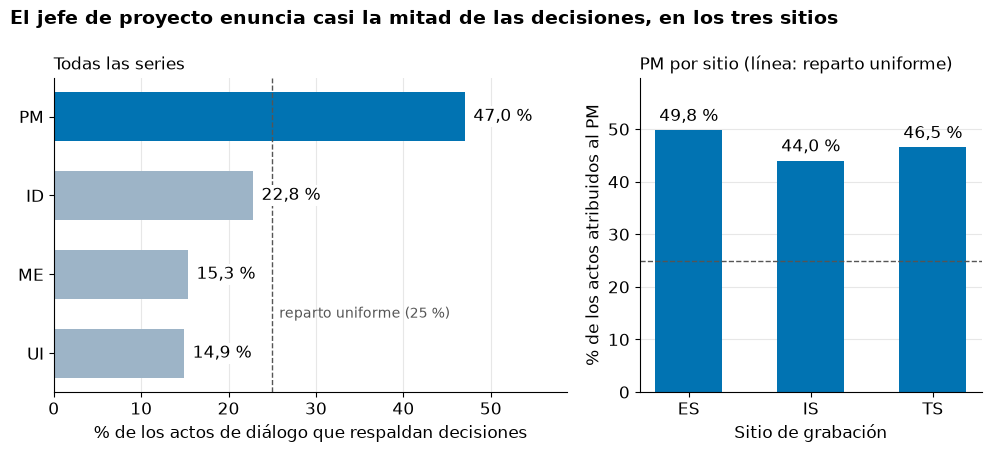

In [2]:
roles = audit.role_authorship(series=SERIES)
overall = roles[roles["site"] == "ALL"].sort_values("share", ascending=False)
by_site = roles[(roles["role"] == "PM") & (roles["site"] != "ALL")].sort_values("site")
N_ACTS = int(overall["count"].sum())
SHARE = dict(zip(overall["role"], overall["share"], strict=True))
PM_SITE = dict(zip(by_site["site"], by_site["share"], strict=True))

with report_style():
    fig = plot_role_authorship(
        roles,
        title="El jefe de proyecto enuncia casi la mitad de las decisiones, en los tres sitios",
    )
    path = save_figure(fig, FIGURES_DIR / "eda-decisiones-por-rol.png")
    display(fig)
EXPORTED.append(path)

display((roles.pivot(index="role", columns="site", values="share") * 100).round(1))
print(f"Actos de diálogo atribuidos: {N_ACTS}")
print({role: round(share * 100, 1) for role, share in SHARE.items()})
print({site: round(share * 100, 1) for site, share in PM_SITE.items()})

In [3]:
def pct(v):
    return f"{es(v * 100, 1)} %"


display(
    Markdown(
        f"""
**Cómo leer la figura.** El panel izquierdo reparte los {es(N_ACTS)} actos de diálogo
atribuidos de las {len(SERIES)} series entre los cuatro roles; la línea punteada marca el
reparto uniforme (25 %). El panel derecho muestra, solo para el jefe de proyecto, la misma
proporción en cada sitio de grabación (ES, IS y TS).

**Qué se observa.** El PM concentra {pct(SHARE["PM"])} de los actos, casi el doble que
cualquier otro rol: ID {pct(SHARE["ID"])}, ME {pct(SHARE["ME"])} y UI {pct(SHARE["UI"])}. La
proporción del PM se mantiene entre {pct(min(PM_SITE.values()))} y
{pct(max(PM_SITE.values()))} en cada sitio por separado (ES {pct(PM_SITE["ES"])}, IS
{pct(PM_SITE["IS"])}, TS {pct(PM_SITE["TS"])}), de modo que el patrón no depende de un sitio
en particular.

**Qué implica.** Las decisiones del corpus reflejan sobre todo la voz de quien preside la
reunión. Es un rasgo del escenario, no un error de los datos, y debe tenerse presente al
interpretar cualquier resultado que dependa de quién enuncia una decisión."""
    )
)


**Cómo leer la figura.** El panel izquierdo reparte los 685 actos de diálogo
atribuidos de las 14 series entre los cuatro roles; la línea punteada marca el
reparto uniforme (25 %). El panel derecho muestra, solo para el jefe de proyecto, la misma
proporción en cada sitio de grabación (ES, IS y TS).

**Qué se observa.** El PM concentra 47,0 % de los actos, casi el doble que
cualquier otro rol: ID 22,8 %, ME 15,3 % y UI 14,9 %. La
proporción del PM se mantiene entre 44,0 % y
49,8 % en cada sitio por separado (ES 49,8 %, IS
44,0 %, TS 46,5 %), de modo que el patrón no depende de un sitio
en particular.

**Qué implica.** Las decisiones del corpus reflejan sobre todo la voz de quien preside la
reunión. Es un rasgo del escenario, no un error de los datos, y debe tenerse presente al
interpretar cualquier resultado que dependa de quién enuncia una decisión.

---

# 2. Acuerdo entre anotadores en la Fase 2 (OE1)

La referencia de OE1 la anotaron dos personas de forma independiente sobre las cuatro series de control de la
Fase 2 (ES2016, IS1003, TS3005 y ES2008). Para cada par de decisiones se compara si existe un enlace
(**existencia**), de qué clase es (**tipo**) y hacia dónde apunta (**dirección**). Se informa el acuerdo simple
(proporción de pares con la misma etiqueta) y el kappa de Cohen, que descuenta el acuerdo esperado por azar.
`afg.annotation.pooled.pooled_agreement_report` junta los pares de las cuatro series. Se usa solo el alcance
**Fase 2**, que es la cifra reportable; el alcance «Fases 1 + 2» es secundario y no se grafica.

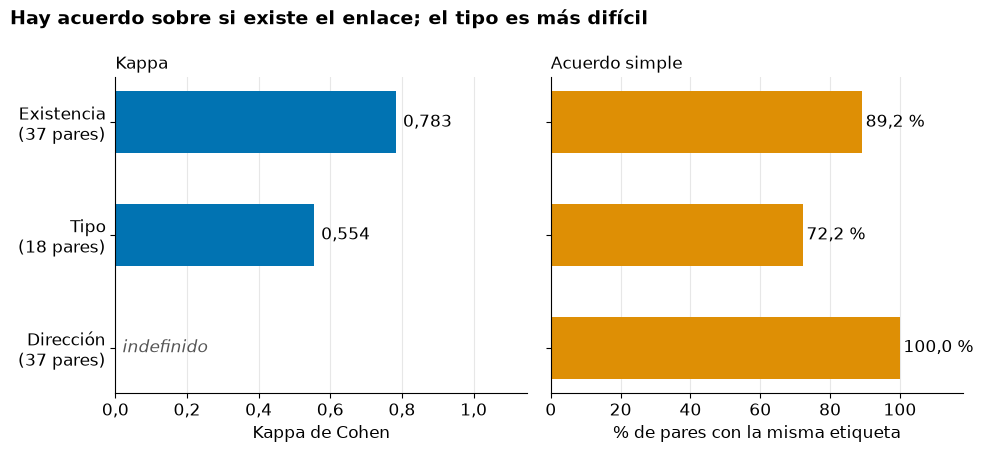

Series de la Fase 2: ES2016, IS1003, TS3005, ES2008


eje,pares,desacuerdos,acuerdo simple,kappa
Existencia,37,4,89.2%,0.783
Tipo,18,5,72.2%,0.554
Dirección,37,0,100.0%,indefinido


In [4]:
report = pooled_agreement_report(load_annotation_plan())
phase2 = next(group for group in report if group.scope == "phase 2")
AXES = {item.axis: item for item in phase2.axes}
LABELS = {"existence": "Existencia", "type": "Tipo", "direction": "Dirección"}
rows = [
    (LABELS[axis], AXES[axis].n_items, AXES[axis].kappa, AXES[axis].percent_agreement)
    for axis in LABELS
]

with report_style():
    fig = plot_agreement_by_axis(
        rows,
        title="Hay acuerdo sobre si existe el enlace; el tipo es más difícil",
    )
    path = save_figure(fig, FIGURES_DIR / "referencia-acuerdo-oe1.png")
    display(fig)
EXPORTED.append(path)

print(f"Series de la Fase 2: {', '.join(phase2.series)}")
table = pd.DataFrame(
    [
        {
            "eje": LABELS[axis],
            "pares": AXES[axis].n_items,
            "desacuerdos": AXES[axis].n_disagreements,
            "acuerdo simple": AXES[axis].percent_agreement,
            "kappa": AXES[axis].kappa,
        }
        for axis in LABELS
    ]
)
display(
    table.style.format({"acuerdo simple": "{:.1%}", "kappa": "{:.3f}"}, na_rep="indefinido").hide(
        axis="index"
    )
)

In [5]:
ex, ty, di = AXES["existence"], AXES["type"], AXES["direction"]
K_EX, K_TY = es(ex.kappa, 3), es(ty.kappa, 3)
display(
    Markdown(
        f"""
**Cómo leer la figura.** Cada fila es un eje de la anotación y entre paréntesis figura el
número de pares comparados. El panel izquierdo muestra el kappa de Cohen y el derecho el
acuerdo simple.

**Qué se observa.**

- **Existencia.** {ex.n_items} pares, acuerdo simple de {pct(ex.percent_agreement)} y kappa
  de {K_EX}: las dos personas casi siempre coinciden en si dos decisiones están enlazadas.
- **Tipo.** {ty.n_items} pares, acuerdo simple de {pct(ty.percent_agreement)} y kappa de
  {K_TY}: coinciden menos en la clase de enlace.
- **Dirección.** {di.n_items} pares con acuerdo simple de {pct(di.percent_agreement)}. El
  kappa queda **indefinido**: en todos los pares ambas personas marcaron la misma dirección,
  con un solo valor posible, y sin variación el kappa no existe. No es cero ni un fallo de
  cálculo; en la figura se escribe «indefinido» y la barra queda vacía.

**Qué implica.** La referencia es estable para decidir si hay un enlace y menos estable para
clasificar su tipo; la exactitud de tipo de cualquier sistema debe leerse con esa cota. Las
cifras son las de la Fase 2 sola; el kappa agrupado de las Fases 1 y 2 es un dato secundario
que no se muestra aquí."""
    )
)


**Cómo leer la figura.** Cada fila es un eje de la anotación y entre paréntesis figura el
número de pares comparados. El panel izquierdo muestra el kappa de Cohen y el derecho el
acuerdo simple.

**Qué se observa.**

- **Existencia.** 37 pares, acuerdo simple de 89,2 % y kappa
  de 0,783: las dos personas casi siempre coinciden en si dos decisiones están enlazadas.
- **Tipo.** 18 pares, acuerdo simple de 72,2 % y kappa de
  0,554: coinciden menos en la clase de enlace.
- **Dirección.** 37 pares con acuerdo simple de 100,0 %. El
  kappa queda **indefinido**: en todos los pares ambas personas marcaron la misma dirección,
  con un solo valor posible, y sin variación el kappa no existe. No es cero ni un fallo de
  cálculo; en la figura se escribe «indefinido» y la barra queda vacía.

**Qué implica.** La referencia es estable para decidir si hay un enlace y menos estable para
clasificar su tipo; la exactitud de tipo de cualquier sistema debe leerse con esa cota. Las
cifras son las de la Fase 2 sola; el kappa agrupado de las Fases 1 y 2 es un dato secundario
que no se muestra aquí.

In [6]:
for path in EXPORTED:
    print(path.relative_to(PROJECT_ROOT))

docs/entregables/figuras/eda-decisiones-por-rol.png
docs/entregables/figuras/referencia-acuerdo-oe1.png
